# Benchmark: solve time and memory against the horizon, with acados

**Question.** How does the solve time of the parallel-in-horizon IPM grow with the horizon $N$, compared with
acados, a state-of-the-art MPC solver written in C?

**Solvers.**

| label | what | depth |
|---|---|---|
| acados | acados v0.6 (C code generation) + HPIPM (Riccati-based IPM, BLASFEO linear algebra), partial condensing at its default horizon, one core | $\Theta(N)$ |
| scan | `parampc`, backend `'scan'`: the IPM with associative-scan Newton steps, compiled by XLA | $\Theta(\log N)$ |
| sweep | `parampc`, backend `'sweep'`: the same IPM with the sequential Riccati recursion | $\Theta(N)$ |
| cuda | `parampc`, backend `'cuda'`: the whole IPM as one CUDA kernel | $\Theta(\log N)$ |
| cuda float32 | the same with `precision='float32'`: the factorization in single precision while the duality measure exceeds $10^{-5}$ | $\Theta(\log N)$ |

`parampc` runs on the CPU with all cores (XLA's default), on **one core** (pinned with `taskset`, like the
single-threaded acados), and on the GPU. acados has no GPU backend.

**Problems.** Both solvers solve the *same* problems, and Section 3 checks that their solutions agree.
1. **Linear MPC**: one constrained QP. A random, open-loop unstable LTI system ($n=8$, $m=4$) with input and state
   boxes tracks a constant state reference, starting where the input bounds are active. Timed: one full QP solve
   (tolerance $10^{-8}$). The reference is nonzero on purpose: when regulating to zero over a long horizon, the
   optimal states decay below $10^{-308}$ and subnormal arithmetic slows C code by an order of magnitude, which XLA
   avoids by flushing to zero.
2. **Quadrotor NMPC**: the slung-load problem of notebook 02. Timed: **one SQP iteration** from the hover initial
   guess, which means linearizing along the horizon and solving the QP subproblem (tolerance $10^{-6}$). acados
   uses `SQP_RTI` with the same Gauss–Newton Hessian and the same Levenberg–Marquardt term, so both solvers take the
   same SQP iterate.

**Metrics.** Median solve time; one-off setup time (JIT compilation for `parampc`, code generation plus C
compilation for acados); peak memory. Every measurement runs in a fresh process (`worker.py`), so its memory is its
own, after one second of untimed solves.

**Machine state.** Timings are only meaningful on an idle machine in a fixed power mode: a laptop's power mode
changes CPU timings severalfold, and another GPU job can slow the GPU rows several times. The notebook logs the
power profile, the load and the GPU's compute processes every 30 s and reports them with the results.

## 0. Import Dependencies

In [1]:
import json
import os
import platform
import subprocess
import sys
import threading
import time

import matplotlib.pyplot as plt
import numpy as np

os.environ['JAX_PLATFORMS'] = 'cpu'      # this kernel only orchestrates; each measurement sets its own device
import worker  # noqa: E402

cpu = next((line.split(':', 1)[1].strip() for line in open('/proc/cpuinfo') if line.startswith('model name')), '?')
gpu = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'], capture_output=True,
                     text=True).stdout.strip()
print(f"python {platform.python_version()} | {os.cpu_count()} logical CPUs: {cpu} | GPU: {gpu or 'none'}")

python 3.12.14 | 8 logical CPUs: 11th Gen Intel(R) Core(TM) i7-11370H @ 3.30GHz | GPU: NVIDIA GeForce RTX 3070 Laptop GPU, 8192 MiB


## 1. Parameter Declaration

- `HORIZONS`: the horizon lengths $N$, powers of two from 16 to 4096.
- `CONFIGS`: which solver runs where. `cores=1` pins the process to one CPU core. `max_N` caps configurations that
  would take too long at large $N$ (the sweep on the GPU is launch-bound, about 1 ms per stage per Newton step).
- `REPEATS`: timed solves per configuration (the median is reported), fewer at large $N$.
- `CPU_CORE`: the core used for single-core runs. Pick one that nothing else is using.

In [2]:
HORIZONS = [16, 32, 64, 128, 256, 512, 1024, 2048, 4096]
PROBLEMS = ['linear', 'quadrotor']
USE_GPU = True
CPU_CORE = 1

CONFIGS = [  # label, solver, device, cores (None = all), max_N
    ('acados', 'acados', 'cpu', 1, None),           # single-threaded C; pinned like the 1-core runs
    ('scan, CPU', 'scan', 'cpu', None, None),
    ('sweep, CPU', 'sweep', 'cpu', None, None),
    ('scan, CPU 1 core', 'scan', 'cpu', 1, None),
    ('sweep, CPU 1 core', 'sweep', 'cpu', 1, None),
    ('scan, GPU', 'scan', 'gpu', None, None),
    ('sweep, GPU', 'sweep', 'gpu', None, 1024),
    ('cuda, GPU', 'cuda', 'gpu', None, None),
    ('cuda float32, GPU', 'cuda32', 'gpu', None, None),
]
if not USE_GPU:
    CONFIGS = [c for c in CONFIGS if c[2] != 'gpu']


def repeats(N):
    return 20 if N <= 256 else 10 if N <= 1024 else 5


RESULTS_FILE = 'results/benchmark_results.json'
STYLE = {'acados': ('k', 'o', '-'), 'scan, CPU': ('tab:blue', 's', '-'), 'sweep, CPU': ('tab:orange', 's', '-'),
         'scan, CPU 1 core': ('tab:blue', 's', ':'), 'sweep, CPU 1 core': ('tab:orange', 's', ':'),
         'scan, GPU': ('tab:blue', '^', '--'), 'sweep, GPU': ('tab:orange', '^', '--'),
         'cuda, GPU': ('tab:red', 'D', '-'), 'cuda float32, GPU': ('tab:purple', 'D', '--')}

## 2. Aux Functions

- `run` launches one measurement in a fresh process and returns its JSON line (fields: see `worker.py`). The
  environment selects the device: `JAX_PLATFORMS=cpu` or `cuda,cpu`, with GPU memory preallocation off so that the
  measured memory is what the solver uses; `taskset` pins single-core runs.
- `MachineLog` samples the power profile, the load average and the GPU's compute processes every 30 s in a
  background thread; processes started by `run` are told apart from foreign ones.
- `crossover` interpolates, in log-log, the horizon from which a configuration is faster than acados.

In [3]:
worker_pids = set()


def run(problem, solver, device, cores, N):
    env = dict(os.environ, JAX_PLATFORMS='cuda,cpu' if device == 'gpu' else 'cpu',
               XLA_PYTHON_CLIENT_PREALLOCATE='false')
    cmd = [sys.executable, 'worker.py', problem, solver, str(N), str(repeats(N))]
    if cores == 1:
        cmd = ['taskset', '-c', str(CPU_CORE)] + cmd
    proc = subprocess.Popen(cmd, env=env, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True)
    worker_pids.add(proc.pid)
    out, err = proc.communicate()
    lines = out.strip().splitlines()
    if proc.returncode != 0 or not lines:
        raise RuntimeError(f'{problem} {solver} N={N} failed:\n{err[-2000:]}')
    return json.loads(lines[-1])


class MachineLog:
    """Power profile, load and GPU compute processes every `period` seconds, in a background thread."""

    def __init__(self, period=30.0):
        self.period, self.samples, self._stop = period, [], threading.Event()
        self._thread = threading.Thread(target=self._loop, daemon=True)

    @staticmethod
    def snapshot():
        try:
            power = open('/sys/firmware/acpi/platform_profile').read().strip()
        except OSError:
            power = 'n/a'
        apps = subprocess.run(['nvidia-smi', '--query-compute-apps=pid', '--format=csv,noheader'], capture_output=True,
                              text=True).stdout.split()
        return dict(time=time.strftime('%H:%M:%S'), power=power, load=os.getloadavg()[0],
                    gpu_pids=[int(p) for p in apps if p.isdigit()])

    def _loop(self):
        self.samples.append(self.snapshot())
        while not self._stop.wait(self.period):
            self.samples.append(self.snapshot())

    def __enter__(self):
        self._thread.start()
        return self

    def __exit__(self, *exc):
        self._stop.set()
        self._thread.join()
        self.samples.append(self.snapshot())

    def summary(self, own_pids):
        powers = sorted({s['power'] for s in self.samples})
        foreign = sorted({p for s in self.samples for p in s['gpu_pids'] if p not in own_pids})
        return dict(samples=len(self.samples), power_profiles=powers, foreign_gpu_pids=foreign,
                    max_load=max(s['load'] for s in self.samples))


def series(problem, label, key):
    Ns = [N for N in HORIZONS if (problem, label, N) in results]
    return np.array(Ns), np.array([results[(problem, label, N)][key] for N in Ns])


def crossover(problem, label):
    """The horizon from which `label` is faster than acados (log-log interpolation), or None."""
    Ns, t = series(problem, label, 'time_ms')
    _, t_ac = series(problem, 'acados', 'time_ms')
    ratio = t_ac[:len(Ns)] / t
    for i in range(len(Ns)):
        if ratio[i] > 1:
            if i == 0:
                return float(Ns[0])
            a, b = np.log(ratio[i - 1]), np.log(ratio[i])
            return float(np.exp(np.log(Ns[i - 1]) + (np.log(Ns[i]) - np.log(Ns[i - 1])) * (-a) / (b - a)))
    return None


sys_ = worker.lti_system()
print("linear:    n = 8, m = 4, |u| <= 1, |x| <= 5, Q = I, R = 0.1 I, Q_N = 10 I, constant reference; spectral radius "
      f"of A = {np.abs(np.linalg.eigvals(sys_['A'])).max():.2f}")
print("quadrotor: n = 8 states, 2 thrusts (+2 slack inputs in parampc), midpoint model, dt = 0.05 s, 10 inequality "
      "rows per stage, Levenberg-Marquardt 0.5")

linear:    n = 8, m = 4, |u| <= 1, |x| <= 5, Q = I, R = 0.1 I, Q_N = 10 I, constant reference; spectral radius of A = 1.05
quadrotor: n = 8 states, 2 thrusts (+2 slack inputs in parampc), midpoint model, dt = 0.05 s, 10 inequality rows per stage, Levenberg-Marquardt 0.5


## 3. Simulation Loop

Every (problem, configuration, $N$) runs once, in its own process, under the machine log. Then the solutions are
checked: for each $N$, every `parampc` configuration must return the acados objective to within the solver
tolerances. That is the evidence that the timings compare solvers doing the same work.

In [4]:
results = {}
t_start = time.time()
with MachineLog() as machine:
    for problem in PROBLEMS:
        for label, solver, device, cores, max_N in CONFIGS:
            for N in HORIZONS:
                if max_N is None or N <= max_N:
                    results[(problem, label, N)] = run(problem, solver, device, cores, N)
            print(f"done: {problem:9s} {label}  ({(time.time() - t_start) / 60:.1f} min)")
state = machine.summary(worker_pids)

os.makedirs(os.path.dirname(RESULTS_FILE), exist_ok=True)
with open(RESULTS_FILE, 'w') as f:
    json.dump(dict(date=time.strftime('%Y-%m-%d'), cpu=cpu, gpu=gpu, machine=state, machine_log=machine.samples,
                   rows=[dict(r, config=lab) for (_, lab, _), r in results.items()]), f, indent=1)

agreement = {}                      # (problem, N) -> largest |objective - acados objective| / acados objective
for (problem, label, N), r in results.items():
    ref = results[(problem, 'acados', N)]['objective']
    agreement[(problem, N)] = max(agreement.get((problem, N), 0.0), abs(r['objective'] - ref) / abs(ref))

done: linear    acados  (0.5 min)


done: linear    scan, CPU  (1.8 min)


done: linear    sweep, CPU  (2.3 min)


done: linear    scan, CPU 1 core  (5.4 min)


done: linear    sweep, CPU 1 core  (6.4 min)


...

done: quadrotor sweep, CPU 1 core  (20.1 min)


done: quadrotor scan, GPU  (23.0 min)


done: quadrotor sweep, GPU  (25.0 min)


done: quadrotor cuda, GPU  (25.9 min)


done: quadrotor cuda float32, GPU  (26.9 min)


## 4. Plotting/Printing Results

In [5]:
print(f"machine during the run: {state['samples']} samples, power profile(s) {state['power_profiles']}, "
      f"max load {state['max_load']:.1f}, foreign GPU processes {state['foreign_gpu_pids'] or 'none'}")


def table(problem, key, fmt):
    labels = [c[0] for c in CONFIGS]
    print(f"{'N':>6} " + " ".join(f"{lab:>18}" for lab in labels))
    for N in HORIZONS:
        row = [results.get((problem, lab, N), {}).get(key) for lab in labels]
        print(f"{N:6d} " + " ".join(f"{fmt.format(v):>18}" if v is not None else f"{'-':>18}" for v in row))


for problem in PROBLEMS:
    print(f"\n==== {problem}: median solve time [ms]")
    table(problem, 'time_ms', '{:.3f}')
    print(f"\n==== {problem}: iterations (IPM for parampc, HPIPM QP iterations for acados)")
    table(problem, 'iters', '{:d}')
    print(f"\n==== {problem}: one-off setup [s] (JIT compilation / code generation + C compilation)")
    table(problem, 'setup_s', '{:.1f}')
    print(f"\n==== {problem}: peak process memory increase [MB]")
    table(problem, 'mem_mb', '{:.1f}')
    print(f"\n==== {problem}: XLA program memory (arguments + outputs + temporaries) [MB]")
    table(problem, 'xla_mb', '{:.2f}')
    print(f"\n==== {problem}: objective agreement with acados (max relative difference over configurations)")
    print("   " + "  ".join(f"N={N}: {agreement[(problem, N)]:.1e}" for N in HORIZONS))

tol = {'linear': 1e-7, 'quadrotor': 1e-5}
assert all(agreement[(p, N)] < tol[p] for p in PROBLEMS for N in HORIZONS), "solvers disagree"
print("\nPASS: every configuration returns the acados solution at every horizon")

machine during the run: 54 samples, power profile(s) ['performance'], max load 7.8, foreign GPU processes none

==== linear: median solve time [ms]
     N             acados          scan, CPU         sweep, CPU   scan, CPU 1 core  sweep, CPU 1 core          scan, GPU         sweep, GPU          cuda, GPU  cuda float32, GPU
    16              0.149              2.229              1.446              1.912              1.257             10.103             16.272              1.775              1.606
    32              0.324              3.477              2.225              2.919              1.940             10.145             25.569              1.782              1.534
    64              0.599              6.316              4.386              5.718              3.932             11.382             48.738              1.967              1.716
   128              1.327             12.402              8.043             11.009              7.321             12.969             95.296 

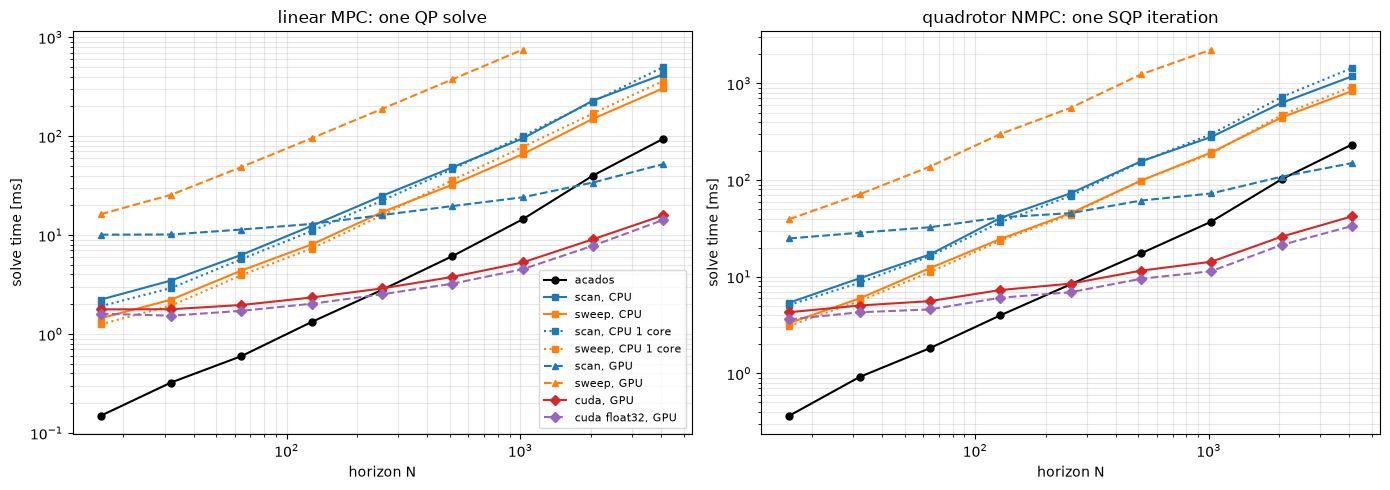

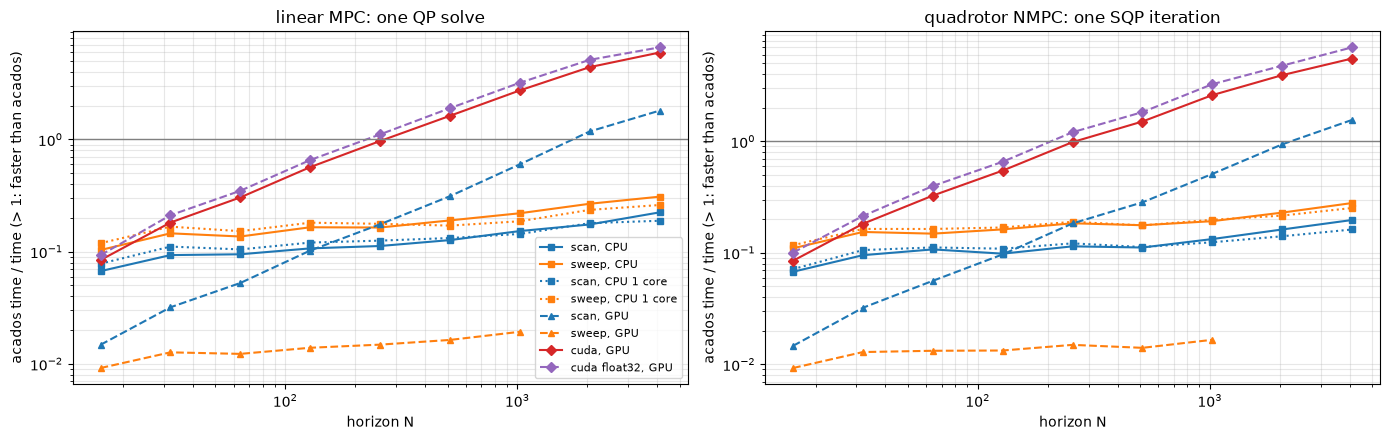

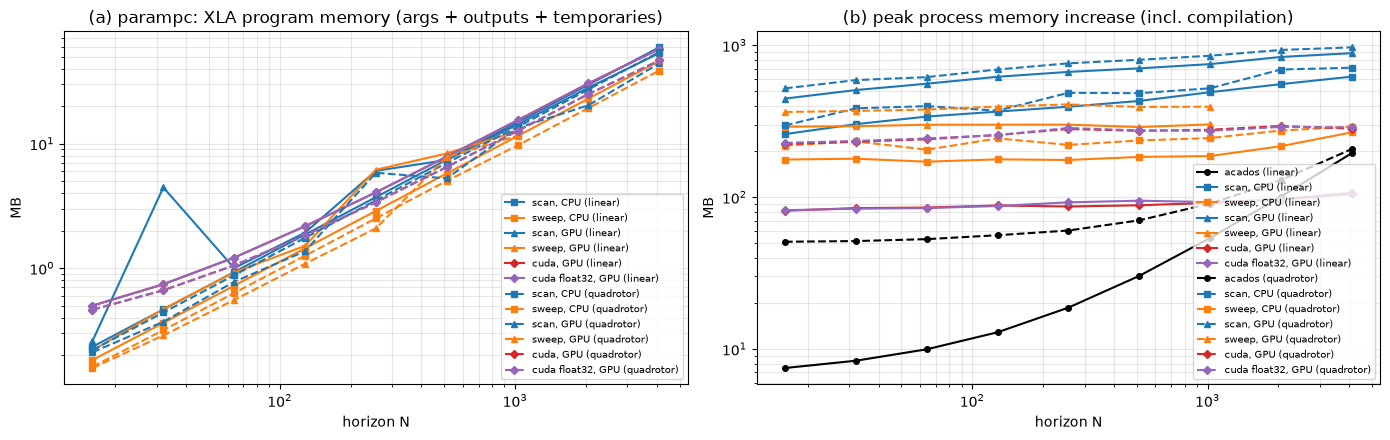

In [6]:
titles = {'linear': 'linear MPC: one QP solve', 'quadrotor': 'quadrotor NMPC: one SQP iteration'}
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, problem in zip(ax, PROBLEMS):
    for label, *_ in CONFIGS:
        Ns, t = series(problem, label, 'time_ms')
        color, marker, ls = STYLE[label]
        a.loglog(Ns, t, color=color, marker=marker, ls=ls, ms=5, label=label)
    a.set(xlabel='horizon N', ylabel='solve time [ms]', title=titles[problem])
    a.grid(alpha=0.3, which='both')
ax[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# speed relative to acados (> 1: faster than acados)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, problem in zip(ax, PROBLEMS):
    Ns_ac, t_ac = series(problem, 'acados', 'time_ms')
    for label, *_ in CONFIGS[1:]:
        Ns, t = series(problem, label, 'time_ms')
        color, marker, ls = STYLE[label]
        a.loglog(Ns, t_ac[:len(Ns)] / t, color=color, marker=marker, ls=ls, ms=5, label=label)
    a.axhline(1.0, color='gray', lw=1)
    a.set(xlabel='horizon N', ylabel='acados time / time (> 1: faster than acados)', title=titles[problem])
    a.grid(alpha=0.3, which='both')
ax[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# memory
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for problem, ls in zip(PROBLEMS, ('-', '--')):
    for label, *_ in CONFIGS:
        color, marker, _ = STYLE[label]
        if label != 'acados' and '1 core' not in label:
            Ns, xla = series(problem, label, 'xla_mb')
            ax[0].loglog(Ns, xla, color=color, marker=marker, ls=ls, ms=4, label=f'{label} ({problem})')
        if '1 core' not in label:
            Ns, mem = series(problem, label, 'mem_mb')
            ax[1].loglog(Ns, mem, color=color, marker=marker, ls=ls, ms=4, label=f'{label} ({problem})')
ax[0].set(xlabel='horizon N', ylabel='MB', title='(a) parampc: XLA program memory (args + outputs + temporaries)')
ax[1].set(xlabel='horizon N', ylabel='MB', title='(b) peak process memory increase (incl. compilation)')
for a in ax:
    a.grid(alpha=0.3, which='both')
    a.legend(fontsize=7)
plt.tight_layout()
plt.show()

In [7]:
print("Speed relative to acados: acados time / configuration time (> 1: faster than acados)\n")
for problem in PROBLEMS:
    print(f"==== {problem}")
    labels = [c[0] for c in CONFIGS[1:]]
    print(f"{'N':>6} {'acados [ms]':>12} " + " ".join(f"{lab:>18}" for lab in labels))
    for N in HORIZONS:
        t_ac = results[(problem, 'acados', N)]['time_ms']
        cells = [f"{t_ac / results[(problem, lab, N)]['time_ms']:.2f}x" if (problem, lab, N) in results else '-'
                 for lab in labels]
        print(f"{N:6d} {t_ac:12.3f} " + " ".join(f"{c:>18}" for c in cells))
    for lab in labels:
        Ns, t = series(problem, lab, 'time_ms')
        _, t_ac = series(problem, 'acados', 'time_ms')
        x = crossover(problem, lab)
        print(f"   {lab:18s} faster than acados from N ~ {x:.0f}" if x else f"   {lab:18s} slower than acados up to "
              f"N = {Ns.max()}", end='')
        print(f"; at N = {Ns.max()}: {t_ac[len(Ns) - 1] / t[-1]:.2f}x, at N = {Ns[0]}: {t_ac[0] / t[0]:.2f}x")
    print()

Speed relative to acados: acados time / configuration time (> 1: faster than acados)

==== linear
     N  acados [ms]          scan, CPU         sweep, CPU   scan, CPU 1 core  sweep, CPU 1 core          scan, GPU         sweep, GPU          cuda, GPU  cuda float32, GPU
    16        0.149              0.07x              0.10x              0.08x              0.12x              0.01x              0.01x              0.08x              0.09x
    32        0.324              0.09x              0.15x              0.11x              0.17x              0.03x              0.01x              0.18x              0.21x
    64        0.599              0.09x              0.14x              0.10x              0.15x              0.05x              0.01x              0.30x              0.35x
   128        1.327              0.11x              0.16x              0.12x              0.18x              0.10x              0.01x              0.57x              0.66x
   256        2.797              0.11x    

**Reading the results.**
- **Scaling.** acados and the sweep grow linearly in $N$ (sequential depth). On the GPU the scan's time grows far
  more slowly: its depth is $\Theta(\log N)$ and the work per level runs in parallel.
- **Constant factors.** On the CPU, and especially on one core, the scan does more work than a Riccati recursion
  (a few matrix products and two solves per combine, about twice as many combines). With no parallel hardware to
  absorb that work it cannot beat hand-optimized sequential C, and acados is the reference point for that.
- **Short horizons.** Through XLA the GPU's floor is kernel launches; the single CUDA kernel removes them, and its
  own floor is the latency of double-precision arithmetic on the GPU.
- **Caveats.** acados runs with its default settings on one core; partial condensing tuned to the horizon could make
  it faster. One laptop with a consumer GPU (weak in double precision); timings move by up to ~15% between
  sessions, so crossovers are approximate. Each measurement solves one QP; batches (`examples/batch.py`) are not
  compared with several acados instances in parallel.